# Бонус. Текст + картинка: CLIP против нашей CNN

Языковые модели и компьютерное зрение встречаются в моделях типа **CLIP** (OpenAI, 2021).
В CLIP две сети:
- **кодировщик картинок** (трансформер для изображений — те же блоки с вниманием, только токены — кусочки картинки 32 × 32 пикселя);
- **кодировщик текста** (трансформер, как наш мини-GPT, с токенами BPE).

Обе сети переводят вход в вектор из 512 чисел. CLIP учили на 400 миллионах пар «картинка + подпись» из интернета так,
чтобы вектор картинки был **близок** к вектору её подписи и далёк от чужих подписей.

Отсюда — **классификация без обучения** (*zero-shot*): чтобы отличить кошек от собак, не нужен ни один пример из CIFAR.
Пишем фразы «a photo of a cat» и «a photo of a dog» и смотрим, к какой из них картинка ближе.

**Что понадобится** (подробно — в `Read.md`):
- пакет `clip` (`pip install git+https://github.com/ultralytics/CLIP.git`);
- веса `ViT-B-32.pt` (~340 МБ) в папке `data/clip`;
- обученные сети `session04/mlp.pt`, `cnn.pt`, `cnn_aug.pt` (шаги 3–5 сессии 4) — для сравнения.

**Структура примера (алгоритм):**
1. Загружаем CLIP и проверочные картинки кошек и собак из сессии 4.
2. Смотрим, как CLIP режет на токены английскую и русскую фразу.
3. Разбираемся с косинусной близостью на игрушечных векторах и кодируем все 2000 картинок.
4. Классифицируем без обучения с разными подписями, смотрим на сами числа близости и сравниваем с нашими сетями.
5. Спрашиваем CLIP о пяти вариантах подписи.
6. Ищем картинки по текстовому запросу.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session05")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())
    import subprocess

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ultralytics/CLIP.git"], check=True)

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.CIFAR10(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех примерах сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `load_names()`, `load_text()` | русские имена из `names.txt` и «Евгений Онегин» (главы 1–8) из `onegin.txt` |
| `CharTokenizer(text)` | словарь символов: `encode` — строка → номера, `decode` — номера → строка, `vocab_size` — размер словаря |
| `name_tokenizer`, `bigram_pairs`, `bigram_counts` | словарь для имён (точка `.` — начало/конец имени), пары «буква → следующая», таблица подсчётов |
| `sample_name(probs, tok)` | придумать имя по таблице вероятностей |
| `apply_temperature(logits, T)` | вероятности из «сырых оценок» с температурой T |
| `MiniGPT`, `Block`, `SelfAttention` | маленький трансформер по символам |
| `save_gpt`, `load_gpt` | сохранить / загрузить GPT вместе со словарём |
| `load_session04()` | модуль `common.py` из сессии 4 (кошки и собаки, `SimpleCNN`) — для бонуса |
| `show()` | показать графики matplotlib |

> Запускайте примеры из папки `session05`, иначе `import common` не найдёт модуль.
> Библиотеки: `pip install -r requirements.txt`. Тексты лежат в этой же папке, интернет не нужен.

## 1. Загрузка CLIP и данных

В CLIP примерно в 1500 раз больше весов, чем в нашей `SimpleCNN`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import torch
from torchvision.transforms.v2 import functional as TF

from common import DATA, load_session04, show

try:
    import clip
    from clip.simple_tokenizer import SimpleTokenizer
except ImportError:
    raise SystemExit("Нет пакета clip — установите его по инструкции из Read.md")

CLIP_DIR = DATA / "clip"
if not (CLIP_DIR / "ViT-B-32.pt").exists():
    print(f"Нет весов {CLIP_DIR / 'ViT-B-32.pt'} — скачиваем один раз (~340 МБ, нужен интернет)")

warnings.filterwarnings("ignore", category=FutureWarning)   # безвредное предупреждение torch.jit при загрузке CLIP
model, preprocess = clip.load("ViT-B/32", device="cpu", download_root=str(CLIP_DIR))
model.eval()
print("Весов в CLIP:", sum(p.numel() for p in model.parameters()))

s4 = load_session04()
test = s4.CatsDogs(train=False)
print("Проверочных картинок из сессии 4:", len(test))

Весов в CLIP: 151277313
Проверочных картинок из сессии 4: 2000


## 2. Токены CLIP

Словарь CLIP построен по английским текстам (BPE из шага 1). Английская фраза — несколько целых слов,
а русская распадается на множество мелких кусочков (даже на половинки букв: `�`). Посмотрим, как это скажется на точности.

In [2]:
# --- 1. Как CLIP режет текст на токены (BPE, как в шаге 1)
tokenizer = SimpleTokenizer()
for phrase in ["a photo of a cat", "фотография кошки"]:
    ids = tokenizer.encode(phrase)
    pieces = [tokenizer.decode([i]) for i in ids]
    print(f"«{phrase}» → {len(ids)} токенов: {pieces}")
print("Английский CLIP видел мало русского текста: кириллица режется на мелкие кусочки байтов.")

«a photo of a cat» → 5 токенов: ['a ', 'photo ', 'of ', 'a ', 'cat ']
«фотография кошки» → 16 токенов: ['фот', 'о�', '�', 'р', 'а', 'ф', 'и', '�', '� ', 'к', 'о', '�', '�', 'к', '�', '� ']
Английский CLIP видел мало русского текста: кириллица режется на мелкие кусочки байтов.


## 3. Косинусная близость и кодирование картинок

`preprocess` растягивает картинку 32 × 32 до 224 × 224 и нормирует цвета так, как привык CLIP.
Каждый вектор делим на его длину — тогда скалярное произведение двух векторов = косинус угла между ними (**косинусная близость**).

In [3]:
@torch.no_grad()
def encode_images(images):
    """Картинки (N, 3, 32, 32) → векторы CLIP длиной 1 (N, 512)."""
    features = []
    for i in range(0, len(images), 100):
        batch = torch.stack([preprocess(TF.to_pil_image(image)) for image in images[i:i + 100]])
        f = model.encode_image(batch)          # 32×32 растягивается до 224×224 — CLIP учили на таком размере
        features.append(f / f.norm(dim=-1, keepdim=True))
        print(f"\r  картинок закодировано: {i + len(batch)}/{len(images)}", end="")
    print()
    return torch.cat(features)


@torch.no_grad()
def encode_texts(texts):
    """Фразы → векторы CLIP длиной 1 (len(texts), 512)."""
    f = model.encode_text(clip.tokenize(texts))
    return f / f.norm(dim=-1, keepdim=True)

### Косинусная близость на игрушке

Представим, что вектор слова — всего два числа: «пушистость» и «лай». Нарисуйте эти стрелки на бумаге:
«кошка» и «котёнок» смотрят почти в одну сторону (близость около 1), «собака» — под большим углом, «машина» — почти в противоположную сторону (близость меньше 0).
У CLIP то же самое, только чисел не 2, а 512, и смысл каждого числа никто не задавал — его выучила сеть.

In [4]:
# Косинусная близость на игрушечных векторах из двух чисел: «пушистость» и «лай»
toy = {"кошка": [0.9, 0.1], "котёнок": [1.0, 0.0], "собака": [0.3, 0.9], "машина": [-0.7, 0.2]}
toy = {word: torch.tensor(v) / torch.tensor(v).norm() for word, v in toy.items()}   # длина 1
for word in ["котёнок", "собака", "машина"]:
    print(f"близость «кошка» и «{word}»: {toy['кошка'] @ toy[word]:+.2f}")
print("1 — смотрят в одну сторону, 0 — не связаны, −1 — противоположны")

print("Кодируем картинки (на процессоре это займёт около минуты)...")
image_features = encode_images(test.images)

близость «кошка» и «котёнок»: +0.99
близость «кошка» и «собака»: +0.42
близость «кошка» и «машина»: -0.93
1 — смотрят в одну сторону, 0 — не связаны, −1 — противоположны
Кодируем картинки (на процессоре это займёт около минуты)...
  картинок закодировано: 2000/2000


## 4. Классификация без обучения против наших сетей

Ожидаемо: CLIP с английскими подписями обгоняет наши сети, хотя **ни разу не видел обучающих картинок** CIFAR —
всё знание о кошках и собаках он получил из подписей в интернете. Фраза «a photo of a …» обычно лучше голого слова:
так выглядят настоящие подписи к фото. А с русскими подписями точность около 50% — это просто угадывание:
в словаре CLIP нет русских слов (пункт 2), и «кошка» для него — набор бессмысленных кусочков.

Примерные результаты: CLIP с «a photo of a cat» — около 91%, `cnn_aug` — около 83%, `cnn` — около 76%, `mlp` — около 62%.

In [5]:
# --- 2. Классификация без обучения: какая фраза ближе к картинке
results = {}
for prompts in [["cat", "dog"], ["a photo of a cat", "a photo of a dog"],
                ["кошка", "собака"], ["фотография кошки", "фотография собаки"]]:
    similarity = image_features @ encode_texts(prompts).T      # косинусная близость, (2000, 2)
    acc = (similarity.argmax(1) == test.labels).float().mean().item()
    results[f"CLIP: «{prompts[0]}»"] = acc
    print(f"CLIP с подписями {prompts}: точность {acc:.1%}")

CLIP с подписями ['cat', 'dog']: точность 90.2%
CLIP с подписями ['a photo of a cat', 'a photo of a dog']: точность 91.0%
CLIP с подписями ['кошка', 'собака']: точность 51.6%
CLIP с подписями ['фотография кошки', 'фотография собаки']: точность 49.5%


### Какие числа получаются на самом деле

Близости картинки к «cat» и к «dog» — около 0.2–0.3 и отличаются всего на сотые доли.
Чтобы превратить их в уверенные вероятности, CLIP умножает их на 100 перед softmax. Это та же **температура** из шага 4, только T = 0.01:
крошечная разница в близости становится заметной разницей в вероятностях.

In [6]:
# Как выглядят сами числа: близости отличаются совсем чуть-чуть, поэтому CLIP умножает их на 100 перед softmax
similarity = image_features[:4] @ encode_texts(["a photo of a cat", "a photo of a dog"]).T
for i, (cat, dog) in enumerate(similarity.tolist()):
    p_cat = torch.softmax(100 * torch.tensor([cat, dog]), dim=0)[0]
    print(f"картинка {i} ({s4.CLASSES_RU[test.labels[i]]}): близость к cat {cat:.3f}, к dog {dog:.3f} → P(кошка) = {p_cat:.0%}")

картинка 0 (кошка): близость к cat 0.214, к dog 0.208 → P(кошка) = 66%
картинка 1 (кошка): близость к cat 0.260, к dog 0.226 → P(кошка) = 97%
картинка 2 (собака): близость к cat 0.238, к dog 0.252 → P(кошка) = 20%
картинка 3 (собака): близость к cat 0.219, к dog 0.261 → P(кошка) = 1%


### Наши сети из сессии 4

In [7]:
for name, dropout in [("mlp", None), ("cnn", 0.0), ("cnn_aug", 0.3)]:
    if not (s4.HERE / f"{name}.pt").exists():
        print(f"Нет session04/{name}.pt — выполните шаги сессии 4, чтобы сравнить")
        continue
    net = s4.MLP() if dropout is None else s4.SimpleCNN(dropout=dropout)
    acc = s4.accuracy(s4.load_model(net, name), test)
    results[f"сессия 4: {name}"] = acc
    print(f"Наша сеть {name} из сессии 4: точность {acc:.1%}")

Наша сеть mlp из сессии 4: точность 61.5%
Наша сеть cnn из сессии 4: точность 75.7%
Наша сеть cnn_aug из сессии 4: точность 83.3%


**Честное сравнение.** CLIP в 1500 раз больше и учился на в 40 000 раз большем числе картинок.
Зато наша CNN маленькая, быстрая и выучена за пару минут на ноутбуке.

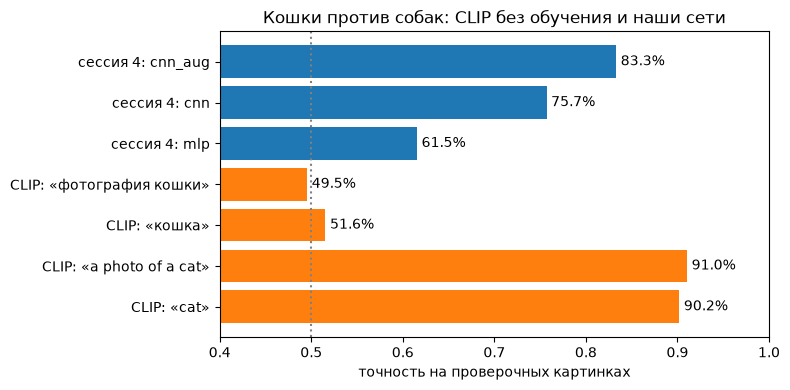

In [8]:
plt.figure(figsize=(8, 4))
names = list(results)
plt.barh(names, [results[n] for n in names], color=["tab:orange" if n.startswith("CLIP") else "tab:blue" for n in names])
for i, n in enumerate(names):
    plt.text(results[n] + 0.005, i, f"{results[n]:.1%}", va="center")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlim(0.4, 1.0)
plt.xlabel("точность на проверочных картинках")
plt.title("Кошки против собак: CLIP без обучения и наши сети")
plt.tight_layout()
plt.savefig("clip_vs_cnn.png", dpi=100)
show()

## 5. Больше двух классов

Наша CNN умеет отвечать только «кошка» или «собака». Подписи CLIP можно менять на ходу: добавим лошадь, машину и лягушку.
Над картинкой — две самые вероятные подписи.

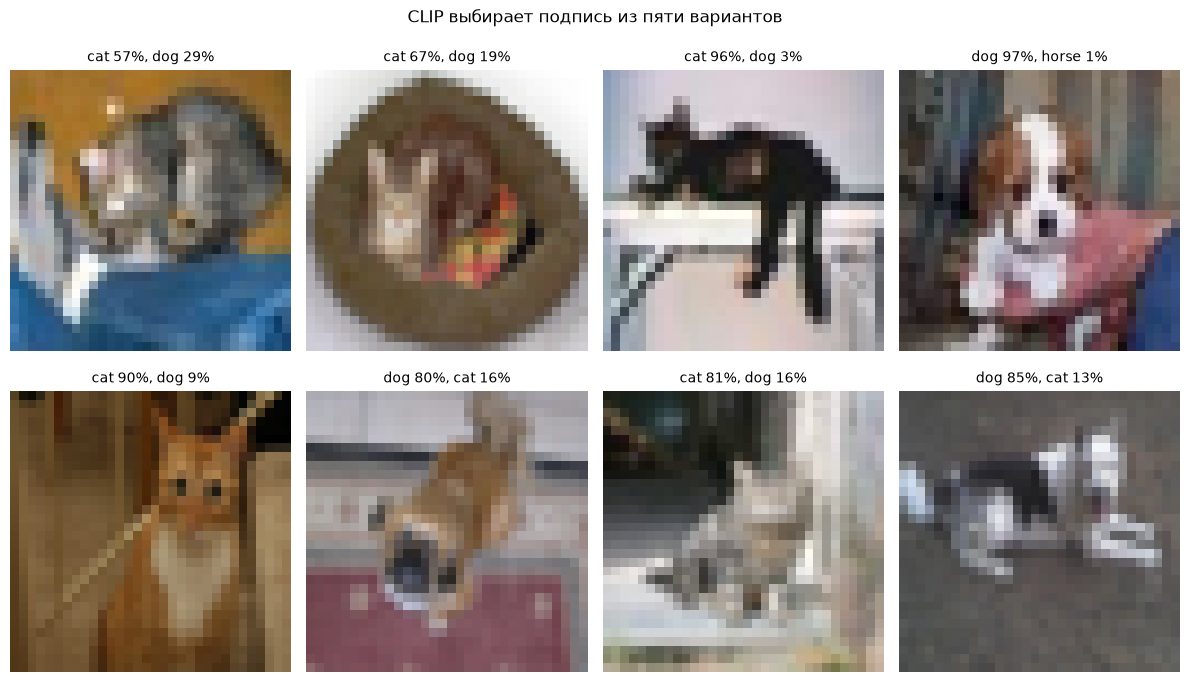

In [9]:
# --- 3. Больше классов, чем две: CLIP можно спросить о чём угодно
labels = ["a photo of a cat", "a photo of a dog", "a photo of a horse", "a photo of a car", "a photo of a frog"]
text_features = encode_texts(labels)
fig, axes = plt.subplots(2, 4, figsize=(12, 7.2))
for ax, i in zip(axes.flat, range(0, 800, 100)):
    probs = (100 * image_features[i] @ text_features.T).softmax(0)   # 100 — «температура» CLIP
    ax.imshow(test.images[i].permute(1, 2, 0))
    best = probs.argsort(descending=True)[:2].tolist()             # две самые вероятные подписи
    ax.set_title(", ".join(f"{labels[j].split()[-1]} {probs[j]:.0%}" for j in best), fontsize=10)
    ax.axis("off")
fig.suptitle("CLIP выбирает подпись из пяти вариантов")
plt.tight_layout()
plt.savefig("clip_labels.png", dpi=100)
show()

## 6. Поиск картинок по тексту

Перевернём задачу: по фразе найдём 5 самых близких картинок. Так работает поиск по фото в телефоне.

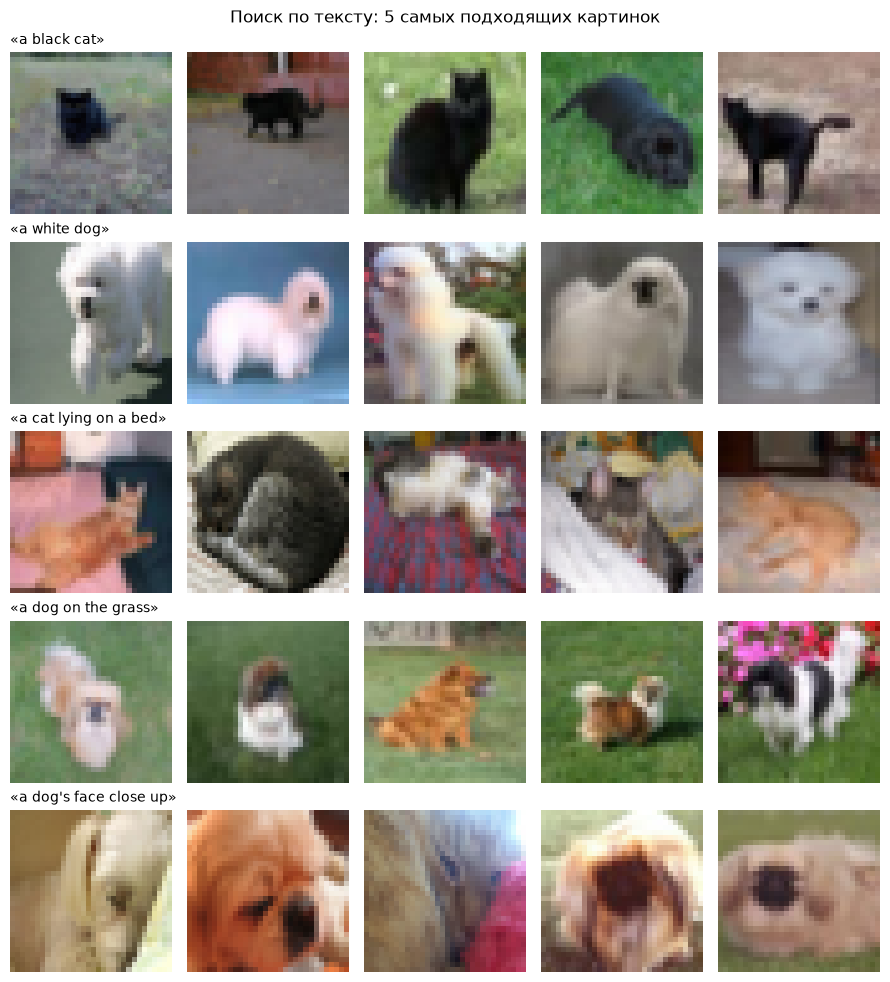

In [10]:
# --- 4. Поиск картинок по тексту
queries = ["a black cat", "a white dog", "a cat lying on a bed", "a dog on the grass", "a dog's face close up"]
similarity = image_features @ encode_texts(queries).T
fig, axes = plt.subplots(len(queries), 5, figsize=(9, 2 * len(queries)))
for row, query in enumerate(queries):
    best = similarity[:, row].argsort(descending=True)[:5]
    for col, i in enumerate(best.tolist()):
        ax = axes[row, col]
        ax.imshow(test.images[i].permute(1, 2, 0))
        ax.axis("off")
        if col == 0:
            ax.set_title(f"«{query}»", loc="left", fontsize=10)
fig.suptitle("Поиск по тексту: 5 самых подходящих картинок")
plt.tight_layout()
plt.savefig("clip_search.png", dpi=100)
show()

## Попробуйте сами

1. Придумайте свои подписи: «a blurry photo of a cat», «a drawing of a dog», «a photo of my pet cat». Какая даёт лучшую точность?
2. Добавьте в игрушку из пункта 3 слово «щенок» со своими двумя числами. Близко ли оно к «собаке»? А к «кошке»?
3. В пункте 4 поменяйте 100 на 10 и на 1000. Как меняются вероятности? Меняется ли точность?
4. Найдите картинки по своим запросам: «a cat in a box», «two dogs», «a puppy».
5. Найдите картинки, на которых CLIP и `cnn_aug` ошибаются по-разному. Есть ли картинки, где ошибаются оба?
6. Добавьте в пункт 5 подпись «a photo of a pipe» (труба из сессий 1–2). Какие картинки CIFAR CLIP считает похожими на трубу?